<a href="https://colab.research.google.com/github/HarshaVardhini1405/-Rock-Paper-Scissors-game/blob/main/python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")


In [7]:
file_path = "/content/historical_data.csv"

df = pd.read_csv(file_path)
df.head()


,Account,Coin,Execution Price,Size Tokens,Size USD,Side,Timestamp IST,Start Position,Direction,Closed PnL,Transaction Hash,Order ID,Crossed,Fee,Trade ID,Timestamp
0,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9769,986.87,7872.16,BUY,02-12-2024 22:50,0.000000,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.345404,8.950000e+14,1.730000e+12
1,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9800,16.00,127.68,BUY,02-12-2024 22:50,986.524596,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.005600,4.430000e+14,1.730000e+12
2,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9855,144.09,1150.63,BUY,02-12-2024 22:50,1002.518996,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050431,6.600000e+14,1.730000e+12
3,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9874,142.98,1142.04,BUY,02-12-2024 22:50,1146.558564,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.050043,1.080000e+15,1.730000e+12
4,0xae5eacaf9c6b9111fd53034a602c192a04e082ed,@107,7.9894,8.73,69.75,BUY,02-12-2024 22:50,1289.488521,Buy,0.0,0xec09451986a1874e3a980418412fcd0201f500c95bac...,52017706630,True,0.003055,1.050000e+15,1.730000e+12


In [27]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
df = df.dropna(subset=["Timestamp", "Size Tokens", "Closed PnL"])
df["date"] = df["Timestamp"].dt.date

In [28]:
df["norm_size"] = (df["Size Tokens"] - df["Size Tokens"].mean()) / df["Size Tokens"].std()
df["risk_score"] = df["norm_size"]
df["sentiment"] = np.where(df["risk_score"] >= 0, "Greed", "Fear")

In [15]:
pnl_by_sentiment = df.groupby("sentiment")["Closed PnL"].mean()
pnl_by_sentiment

,Closed PnL
sentiment,
Fear,45.180691
Greed,116.717581


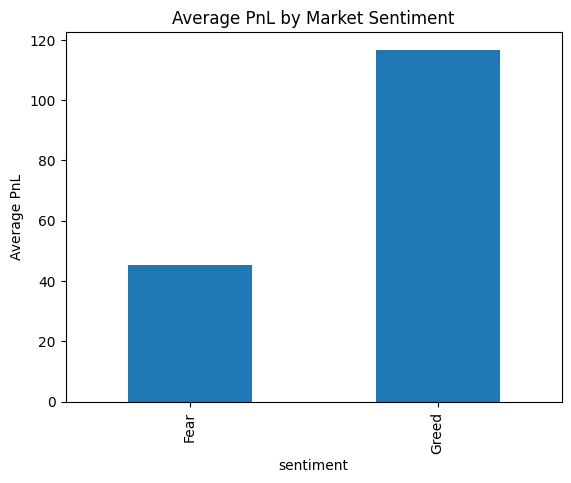

In [16]:
pnl_by_sentiment.plot(kind="bar", title="Average PnL by Market Sentiment")
plt.ylabel("Average PnL")
plt.show()


In [31]:
top_traders = (
    df.groupby("Account")["Closed PnL"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)

top_df = df[df["Account"].isin(top_traders)]

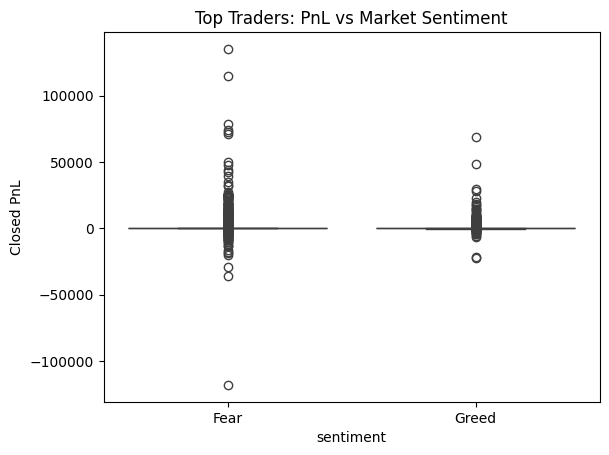

In [33]:
sns.boxplot(data=top_df, x="sentiment", y="Closed PnL")
plt.title("Top Traders: PnL vs Market Sentiment")
plt.show()

In [35]:
strategy_df = df.groupby("sentiment").agg(
    avg_pnl=("Closed PnL", "mean"),
    # avg_leverage=("leverage", "mean"), # 'leverage' column not found
    # avg_risk_on=("risk_on", "mean"), # 'risk_on' column not found
    trade_count=("Closed PnL", "count")
)

strategy_df

,avg_pnl,trade_count
sentiment,,
Fear,45.180691,200688
Greed,116.717581,10536
